In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

conn = sqlite3.connect("Chinook_Sqlite.sqlite")

# Check the connection by listing the tables
pd.read_sql_query("SELECT name FROM sqlite_master WHERE type='table';", conn)

,name
0,Album
1,Artist
2,Customer
3,Employee
4,Genre
5,Invoice
6,InvoiceLine
7,MediaType
8,Playlist
9,PlaylistTrack


# SQL-Based Analysis of Product Sales (Chinook Database)

**Goal:** use SQL to answer key business questions about a digital music store: top-selling products, revenue per country, and monthly performance.

**Tools:** SQLite, Python (sqlite3, pandas), matplotlib

**Note:** the dataset does not state a currency, so revenue is shown as recorded.

### 1. Which tracks sell the most?
We add up the units sold for each track and join to the Track table to get the song name.

In [2]:
query1 = """
-- Top-selling tracks by units sold
SELECT Track.Name AS track, SUM(InvoiceLine.Quantity) AS units_sold
FROM InvoiceLine
JOIN Track ON InvoiceLine.TrackId = Track.TrackId
GROUP BY Track.TrackId
ORDER BY units_sold DESC, Track.Name
LIMIT 10;
"""
top_tracks = pd.read_sql_query(query1, conn)
top_tracks

,track,units_sold
0,A Cor Do Sol,2
1,A Melhor Forma,2
2,A Novidade (Live),2
3,"Abraham, Martin And John",2
4,Aces High,2
5,All Along The Watchtower,2
6,Amor De Muito,2
7,Ando Meio Desligado,2
8,As Rosas Não Falam (Beth Carvalho),2
9,Azul,2


**Insight:** every one of the top 10 tracks sold only 2 units, so there is no standout hit. Track sales are spread thinly across a large catalog.

### 2. Which countries bring in the most revenue?
The database has no region column, so country is used as the region. Invoice already stores each purchase total, so no JOIN is needed.

In [3]:

query2 = """
-- Revenue per country
SELECT BillingCountry AS country, ROUND(SUM(Total), 2) AS revenue
FROM Invoice
GROUP BY BillingCountry
ORDER BY revenue DESC;
"""
country_revenue = pd.read_sql_query(query2, conn)
country_revenue.head(10)

,country,revenue
0,USA,523.06
1,Canada,303.96
2,France,195.10
3,Brazil,190.10
4,Germany,156.48
5,United Kingdom,112.86
6,Czech Republic,90.24
7,Portugal,77.24
8,India,75.26
9,Chile,46.62


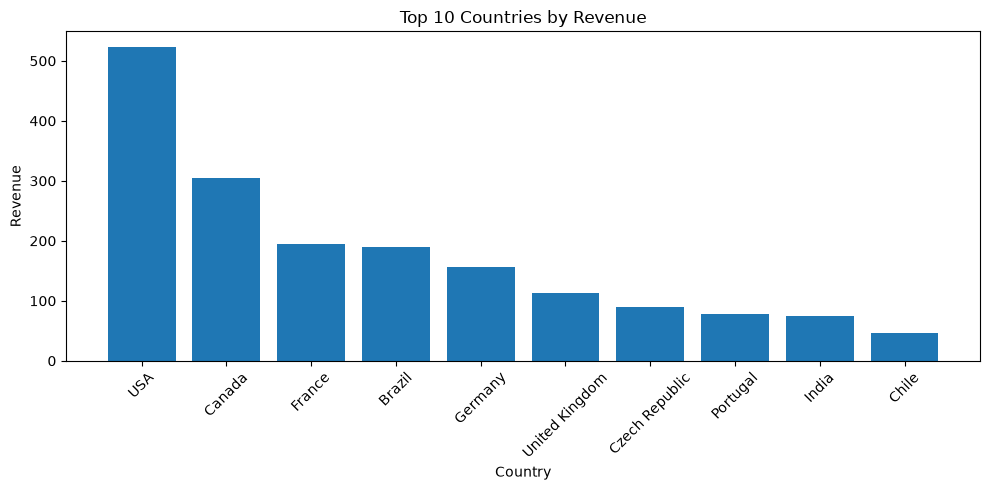

In [4]:
top10 = country_revenue.head(10)

plt.figure(figsize=(10, 5))
plt.bar(top10["country"], top10["revenue"])
plt.title("Top 10 Countries by Revenue")
plt.xlabel("Country")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [5]:
pd.read_sql_query("""
SELECT Country, COUNT(*) AS customers
FROM Customer
GROUP BY Country
ORDER BY customers DESC;
""", conn).head(5)

,Country,customers
0,USA,13
1,Canada,8
2,France,5
3,Brazil,5
4,Germany,4


In [6]:
spend_per_customer = pd.read_sql_query("""
SELECT Invoice.BillingCountry AS country,
       COUNT(DISTINCT Customer.CustomerId) AS customers,
       ROUND(SUM(Invoice.Total), 2) AS revenue,
       ROUND(SUM(Invoice.Total) * 1.0 / COUNT(DISTINCT Customer.CustomerId), 2) AS revenue_per_customer
FROM Invoice
JOIN Customer ON Invoice.CustomerId = Customer.CustomerId
GROUP BY Invoice.BillingCountry
ORDER BY revenue DESC
LIMIT 5;
""", conn)
spend_per_customer

,country,customers,revenue,revenue_per_customer
0,USA,13,523.06,40.24
1,Canada,8,303.96,37.99
2,France,5,195.10,39.02
3,Brazil,5,190.10,38.02
4,Germany,4,156.48,39.12


**Insight:** The USA leads in revenue with 523.06, followed by Canada (303.96) and France (195.10). The USA also has the most customers (13, against 8 for Canada and 5 for France). Average spending per customer is similar in all three: about 40.2 in the USA, 38.0 in Canada and 39.0 in France. So the USA's lead comes mainly from having more customers, not from customers spending more.

### 3. How does revenue change month by month?
`strftime` cuts each invoice date down to year and month so purchases can be grouped by month.

In [7]:
query3 = """
-- Monthly revenue
SELECT strftime('%Y-%m', InvoiceDate) AS month,
       ROUND(SUM(Total), 2) AS revenue
FROM Invoice
GROUP BY month
ORDER BY month;
"""
monthly = pd.read_sql_query(query3, conn)
monthly

,month,revenue
0,2009-01,35.64
1,2009-02,37.62
2,2009-03,37.62
3,2009-04,37.62
4,2009-05,37.62
5,2009-06,37.62
6,2009-07,37.62
7,2009-08,37.62
8,2009-09,37.62
9,2009-10,37.62


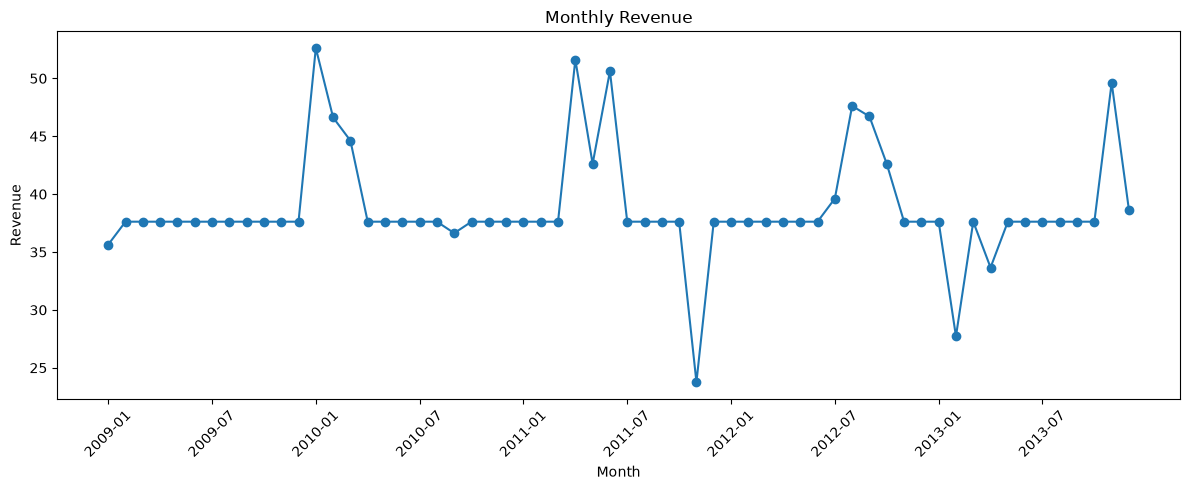

In [8]:
plt.figure(figsize=(12, 5))
plt.plot(monthly["month"], monthly["revenue"], marker="o")
plt.title("Monthly Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(monthly["month"][::6], rotation=45)
plt.tight_layout()
plt.show()

In [9]:
yearly = pd.read_sql_query("""
SELECT strftime('%Y', InvoiceDate) AS year,
       ROUND(SUM(Total), 2) AS revenue
FROM Invoice
GROUP BY year
ORDER BY year;
""", conn)
yearly

,year,revenue
0,2009,449.46
1,2010,481.45
2,2011,469.58
3,2012,477.53
4,2013,450.58


In [10]:
monthly.sort_values("revenue", ascending=True).head(5)

,month,revenue
34,2011-11,23.76
49,2013-02,27.72
51,2013-04,33.66
0,2009-01,35.64
20,2010-09,36.63


**Insight:** Monthly revenue ranged from 23.76 (November 2011) to 52.62 (January 2010). Yearly totals stayed close to each other, between about 450 and 481, so there is no sustained growth or decline over the five years, only a small rise in 2010 and a dip in 2013. The highest and lowest months fall in different seasons and different years (for example, November was the lowest month in 2011 but one of the highest in 2013), so the data shows no clear seasonal pattern.

### 4. Which artists generate the most revenue?
This needs a four-table JOIN: InvoiceLine (the sale) to Track (the song) to Album to Artist.

In [11]:
query4 = """
-- Top 10 artists by revenue
SELECT Artist.Name AS artist,
       ROUND(SUM(InvoiceLine.UnitPrice * InvoiceLine.Quantity), 2) AS revenue
FROM InvoiceLine
JOIN Track  ON InvoiceLine.TrackId = Track.TrackId
JOIN Album  ON Track.AlbumId = Album.AlbumId
JOIN Artist ON Album.ArtistId = Artist.ArtistId
GROUP BY Artist.ArtistId
ORDER BY revenue DESC
LIMIT 10;
"""
top_artists = pd.read_sql_query(query4, conn)
top_artists

,artist,revenue
0,Iron Maiden,138.60
1,U2,105.93
2,Metallica,90.09
3,Led Zeppelin,86.13
4,Lost,81.59
5,The Office,49.75
6,Os Paralamas Do Sucesso,44.55
7,Deep Purple,43.56
8,Faith No More,41.58
9,Eric Clapton,39.60


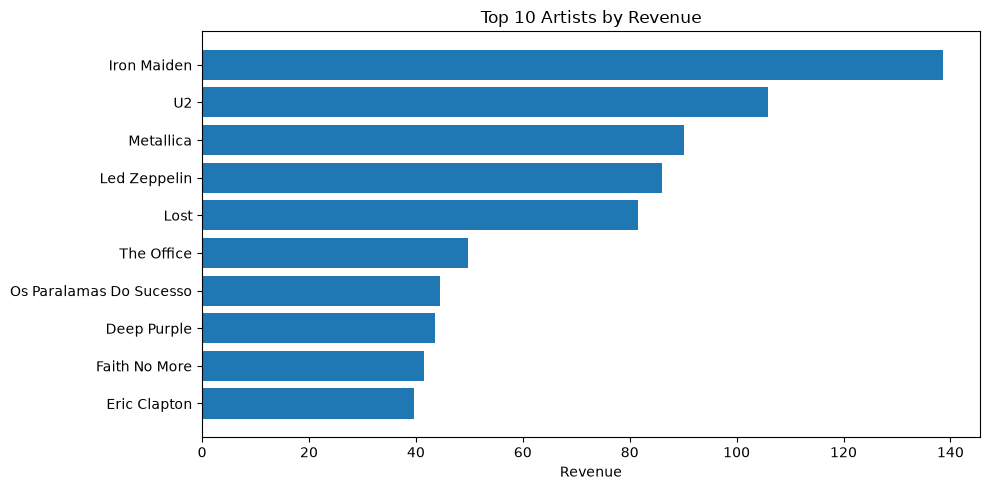

In [12]:
plt.figure(figsize=(10, 5))
plt.barh(top_artists["artist"][::-1], top_artists["revenue"][::-1])
plt.title("Top 10 Artists by Revenue")
plt.xlabel("Revenue")
plt.tight_layout()
plt.show()

In [13]:
pd.read_sql_query("""
SELECT Artist.Name AS artist, MediaType.Name AS media_type, COUNT(*) AS tracks
FROM Track
JOIN Album     ON Track.AlbumId = Album.AlbumId
JOIN Artist    ON Album.ArtistId = Artist.ArtistId
JOIN MediaType ON Track.MediaTypeId = MediaType.MediaTypeId
WHERE Artist.Name IN ('Lost', 'The Office', 'Iron Maiden')
GROUP BY Artist.Name, MediaType.Name;
""", conn)

,artist,media_type,tracks
0,Iron Maiden,MPEG audio file,202
1,Iron Maiden,Protected AAC audio file,11
2,Lost,Protected MPEG-4 video file,92
3,The Office,Protected MPEG-4 video file,53


**Insight:** Iron Maiden (138.60), U2 (105.93) and Metallica (90.09) generate the most revenue, and the top 10 artists together account for about 31% of total revenue (721.38 of 2,328.60). Two of the top six, Lost and The Office, are TV series (video files), so the store sells video as well as music. Iron Maiden has the largest catalog among them (213 tracks), which fits the earlier finding that no single track sold more than 2 units: revenue builds from many tracks each selling a little.

### 5. Bonus: ranking countries with a window function
`RANK() OVER (...)` numbers each country by revenue without collapsing the rows.

In [14]:
query5 = """
-- Rank countries by revenue using a window function
SELECT BillingCountry AS country,
       ROUND(SUM(Total), 2) AS revenue,
       RANK() OVER (ORDER BY SUM(Total) DESC) AS revenue_rank
FROM Invoice
GROUP BY BillingCountry;
"""
ranked = pd.read_sql_query(query5, conn)
ranked.head(10)

,country,revenue,revenue_rank
0,USA,523.06,1
1,Canada,303.96,2
2,France,195.10,3
3,Brazil,190.10,4
4,Germany,156.48,5
5,United Kingdom,112.86,6
6,Czech Republic,90.24,7
7,Portugal,77.24,8
8,India,75.26,9
9,Chile,46.62,10


In [15]:
ranked[ranked.duplicated("revenue_rank", keep=False)]

,country,revenue,revenue_rank
10,Ireland,45.62,11
11,Hungary,45.62,11
17,Spain,37.62,18
18,Poland,37.62,18
19,Italy,37.62,18
20,Denmark,37.62,18
21,Belgium,37.62,18
22,Australia,37.62,18
23,Argentina,37.62,18


**Insight:** The window function ranks all countries by revenue without collapsing the rows: the USA is first (523.06), then Canada (303.96), France (195.10), Brazil (190.10) and Germany (156.48). France and Brazil are separated by only 5.00, so their positions are close. The data also has ties: Ireland and Hungary share rank 11 (45.62 each), and seven countries share rank 18 (37.62 each). RANK gives tied countries the same rank and skips the numbers that follow, which is why there is no rank 12.

## Summary of findings
- **Products:** no single track dominates. The top 10 tracks each sold only 2 units, so sales are spread across a large catalog.
- **Artists:** Iron Maiden (138.60), U2 (105.93) and Metallica (90.09) earn the most. Lost and The Office are video series, so the store sells video as well as music.
- **Regions:** the USA leads with 523.06, ahead of Canada (303.96) and France (195.10), and it also has the most customers (13).
- **Trend:** monthly revenue ranges from 23.76 to 52.62, and yearly totals stay between about 450 and 481. Revenue is roughly flat over 2009 to 2013, with no clear seasonal pattern.
- **Skills shown:** JOINs across up to four tables, GROUP BY and aggregates, date functions, and a window function (RANK).